In [1]:
# Licensed to the Apache Software Foundation (ASF) under one
# or more contributor license agreements.  See the NOTICE file
# distributed with this work for additional information
# regarding copyright ownership.  The ASF licenses this file
# to you under the Apache License, Version 2.0 (the
# "License"); you may not use this file except in compliance
# with the License.  You may obtain a copy of the License at
#
#   http://www.apache.org/licenses/LICENSE-2.0
#
# Unless required by applicable law or agreed to in writing,
# software distributed under the License is distributed on an
# "AS IS" BASIS, WITHOUT WARRANTIES OR CONDITIONS OF ANY
# KIND, either express or implied.  See the License for the
# specific language governing permissions and limitations
# under the License.

# ML Training

This notebook runs the example in `application.py` one step at a time. Run it from the `examples/ml-training` directory, because it imports `application.py`.

The application trains a model one epoch at a time. It halts for a review, and a person decides to approve the model, continue the training, or reject the model.

In [ ]:
!pip install -r requirements.txt

In [2]:
from application import application, review_summary

## Build the application

`application()` builds the state machine. The diagram needs Graphviz. If you do not have Graphviz, look at `statemachine.png`.

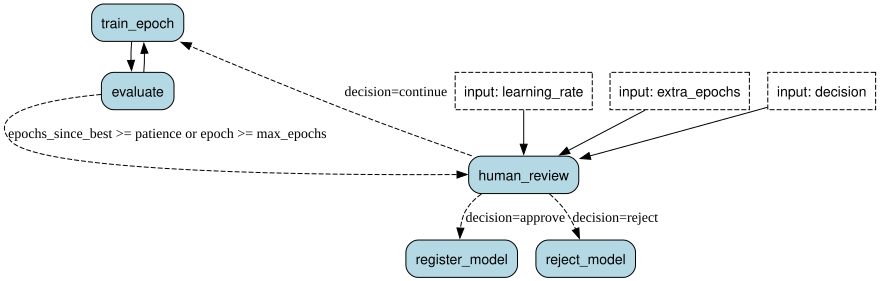

In [3]:
app = application(max_epochs=10, patience=3)
app.visualize(include_conditions=True)

## Train until the review

`halt_before=["human_review"]` tells Burr to stop before the review. The stop rule is a transition condition: `epochs_since_best >= patience or epoch >= max_epochs`.

In [4]:
app.run(halt_before=["human_review"])
print("next action:", app.get_next_action().name)
print(review_summary(app.state))

next action: human_review
Trained 10 epochs. Stopped: reached max_epochs.
Best validation accuracy: 0.9044 at epoch 10 of 10
Checkpoint: checkpoints\79582529-336c-494e-8c8d-1f8148983b63\epoch_10.joblib
Last 5 epochs: 0.893, 0.900, 0.896, 0.902, 0.904
Learning rate: 0.001


## Resume the run

Burr saved the state after each step in `ml_training.db`. A new process can build the application again with the same `app_id` and continue at the review. The next cell does this in the same process.

In [5]:
resumed = application(app_id=app.uid)
print("epochs:", resumed.state["epoch"])
print("next action:", resumed.get_next_action().name)

epochs: 10
next action: human_review


## Continue the training

The decision of the reviewer is an input of the `human_review` action. `continue` trains for a maximum of `extra_epochs` more epochs. Then the application halts before the review again.

The reviewer can also give a new `learning_rate`. The summary above shows that the accuracy rises slowly with a learning rate of 0.001, so this cell continues with 0.01.

In [6]:
resumed.run(
    halt_before=["human_review"],
    inputs={"decision": "continue", "extra_epochs": 5, "learning_rate": 0.01},
)
print(review_summary(resumed.state))

Trained 15 epochs. Stopped: reached max_epochs.
Best validation accuracy: 0.9422 at epoch 15 of 15
Checkpoint: checkpoints\79582529-336c-494e-8c8d-1f8148983b63\epoch_15.joblib
Last 5 epochs: 0.913, 0.911, 0.931, 0.933, 0.942
Learning rate: 0.01


## Approve the model

`approve` moves the application to `register_model`, which copies the best checkpoint to `model.joblib`.

In [7]:
resumed.run(halt_after=["register_model", "reject_model"], inputs={"decision": "approve"})
print("final model:", resumed.state["final_model"])

final model: checkpoints\79582529-336c-494e-8c8d-1f8148983b63\model.joblib


To see each step of this run, run `burr` in a terminal and open the project `demo_ml_training`.